# RNN 실습 4: 실제 기온으로 내일 최저기온 예측 (RNN · LSTM · GRU)

| 순서 | 내용 | 시간 |
|---|---|---|
| 1 | 데이터 불러오기·그래프 | 3분 |
| 2 | 시간순 분할 → 정규화 → 윈도우 | 10분 |
| 3 | 기준선 "내일 = 오늘" | 5분 |
| 4 | RNN 학습·평가 | 5분 |
| 5 | LSTM·GRU로 바꿔 비교 | 5분 |
| 6 | 문제 (코드를 직접 고쳐 보기) | 남는 시간·과제 |

데이터: 호주 멜버른 일별 최저기온 1981~1990년 (3,650일)

In [26]:
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
df = pd.read_csv(URL, parse_dates=["Date"])
print(df.shape)
df.head()

(3650, 2)


,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


## 1. 데이터 그래프

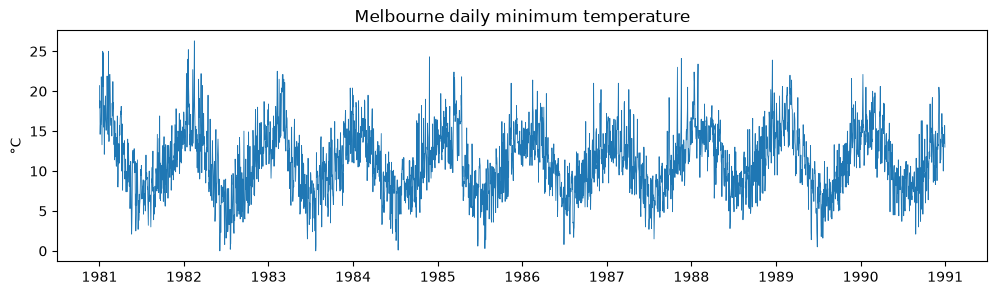

In [27]:
plt.figure(figsize=(12, 3))
plt.plot(df["Date"], df["Temp"], linewidth=0.6)
plt.title("Melbourne daily minimum temperature"); plt.ylabel("°C"); plt.show()

## 2. 시간순 분할 → 정규화 → 윈도우

**① 시간순 분할** (섞어서 나누면 안 됨: 미래 데이터로 과거를 맞히는 컨닝이 됨)

| 구분 | 기간 |
|---|---|
| train | 1981 ~ 1988 |
| val | 1989 |
| test | 1990 |

**② 정규화**: train의 최솟값·최댓값으로 0~1로 바꿈. val·test도 **train 기준**으로 바꿈 (test 정보를 미리 보면 안 됨).

정규화를 하는 이유
- **tanh 포화 막기**: 20°C를 그대로 넣으면 tanh(20) = 1.00, tanh(24) = 1.00으로 같아져서 구별 못 하고 미분도 0에 가까워짐. 0~1로 바꾸면 0.64, 0.72로 구별됨
- **학습 안정**: 값이 0~1 근처면 작은 w 초깃값·학습률과 잘 맞아 학습이 고르게 진행됨
- **단위 맞추기**: 기온·습도·기압처럼 단위가 다른 값을 같이 넣을 때 숫자가 큰 값이 결과를 좌우하지 않게 함

**③ 윈도우**: 지난 30일 → 다음 날 1개

In [28]:
temp = torch.tensor(df["Temp"].values, dtype=torch.float32)
year = df["Date"].dt.year.values
i_val, i_test = (year < 1989).sum(), (year < 1990).sum()     # 1989, 1990이 시작하는 위치
print("train / val / test 일수:", i_val, i_test - i_val, len(temp) - i_test)

t_min, t_max = temp[:i_val].min(), temp[:i_val].max()      # train 기준
scale = lambda v: (v - t_min) / (t_max - t_min)             # °C → 0~1
unscale = lambda v: v * (t_max - t_min) + t_min             # 0~1 → °C
s = scale(temp)

WINDOW = 30
def make_windows(start, end):
    """target(맞힐 날)이 [start, end) 구간에 있는 윈도우만 만들기"""
    idx = range(max(start, WINDOW), end)
    X = torch.stack([s[i - WINDOW:i] for i in idx]).unsqueeze(-1)   # (개수, 30, 1)
    y = torch.stack([s[i] for i in idx]).unsqueeze(-1)              # (개수, 1)
    return X, y

X_train, y_train = make_windows(0, i_val)
X_val, y_val = make_windows(i_val, i_test)
X_test, y_test = make_windows(i_test, len(s))
print("X_train", tuple(X_train.shape), "X_val", tuple(X_val.shape), "X_test", tuple(X_test.shape))

train / val / test 일수: 2920 365 365
X_train (2890, 30, 1) X_val (365, 30, 1) X_test (365, 30, 1)


> val·test 윈도우의 앞부분 30일은 이전 해 데이터를 입력으로 씀. **입력으로 과거를 보는 건 괜찮음.** 맞힐 날(target)만 겹치지 않으면 됨.

## 3. 기준선: "내일 최저기온 = 오늘 최저기온"
모델을 만들기 전에, 아무것도 학습하지 않은 가장 단순한 방법의 점수를 먼저 구함. RNN이 이것보다 나아야 의미가 있음.

평가 지표 **MAE** = 예측과 실제의 차이(절댓값)의 평균, 단위 °C

In [29]:
def mae_celsius(pred, y):
    return (unscale(pred) - unscale(y)).abs().mean().item()

baseline_pred = X_test[:, -1, :]              # 윈도우의 마지막 날 = 오늘
print(f"기준선 test MAE: {mae_celsius(baseline_pred, y_test):.2f} °C")

기준선 test MAE: 2.02 °C


## 4. RNN 학습
학습 배치는 섞어도 됨(`shuffle=True`): 윈도우 하나하나가 독립된 문제이기 때문. 분할은 시간순, 배치는 섞기.

In [30]:
class TempModel(nn.Module):
    def __init__(self, cell="rnn", hidden=32):
        super().__init__()
        Cell = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell]   # 이름만 바꾸면 됨
        self.rnn = Cell(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])       # many-to-one: 마지막 시점만

def train_model(cell, epochs=30):
    torch.manual_seed(0)
    model = TempModel(cell)
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
    best, history = float("inf"), []
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        model.eval()
        with torch.no_grad():
            val_mae = mae_celsius(model(X_val), y_val)
        history.append(val_mae)
        if val_mae < best:                                  # 검증 MAE가 가장 좋을 때 저장
            best = val_mae
            torch.save(model.state_dict(), f"best_{cell}.pt")
        if epoch % 5 == 0:
            print(f"[{cell}] epoch {epoch:2d} | val MAE {val_mae:.2f} °C")
    model.load_state_dict(torch.load(f"best_{cell}.pt"))
    with torch.no_grad():
        test_mae = mae_celsius(model(X_test), y_test)
    print(f"[{cell}] 가장 좋은 val MAE {best:.2f} °C → test MAE {test_mae:.2f} °C")
    return model, history, test_mae

rnn_model, rnn_hist, rnn_mae = train_model("rnn")

[rnn] epoch  5 | val MAE 1.92 °C
[rnn] epoch 10 | val MAE 1.82 °C
[rnn] epoch 15 | val MAE 1.76 °C
[rnn] epoch 20 | val MAE 1.76 °C
[rnn] epoch 25 | val MAE 1.91 °C
[rnn] epoch 30 | val MAE 1.74 °C
[rnn] 가장 좋은 val MAE 1.73 °C → test MAE 1.74 °C


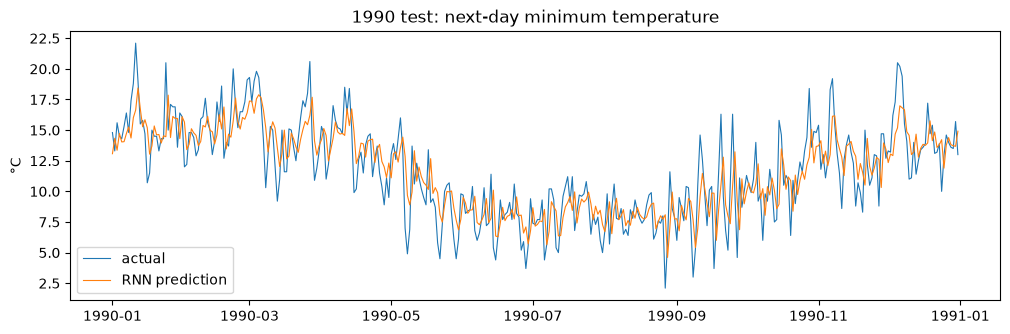

In [31]:
rnn_model.eval()
with torch.no_grad():
    pred = unscale(rnn_model(X_test)).squeeze()
actual = unscale(y_test).squeeze()
days = df["Date"].values[i_test:]

plt.figure(figsize=(12, 3.5))
plt.plot(days, actual, linewidth=0.8, label="actual")
plt.plot(days, pred, linewidth=0.8, label="RNN prediction")
plt.title("1990 test: next-day minimum temperature"); plt.ylabel("°C"); plt.legend(); plt.show()

## 5. LSTM, GRU로 바꿔서 비교
RNN의 장기 의존성 문제(기울기 소실)를 줄이려고 만든 구조.
- **LSTM**: 게이트 3개(잊기·입력·출력) + 셀 상태 C
- **GRU**: 게이트 2개(리셋·업데이트), LSTM을 간단하게 만든 버전

코드는 `nn.RNN` → `nn.LSTM` / `nn.GRU` 이름만 바뀜.

In [32]:
lstm_model, lstm_hist, lstm_mae = train_model("lstm")
gru_model, gru_hist, gru_mae = train_model("gru")

count = lambda m: sum(p.numel() for p in m.parameters())
print()
print(f"{'방법':8s}{'test MAE (°C)':>14s}{'파라미터 수':>12s}")
print(f"{'기준선':8s}{mae_celsius(baseline_pred, y_test):>14.2f}{'-':>12s}")
for name, m, mae in [("RNN", rnn_model, rnn_mae), ("LSTM", lstm_model, lstm_mae), ("GRU", gru_model, gru_mae)]:
    print(f"{name:8s}{mae:>14.2f}{count(m):>12,d}")

[lstm] epoch  5 | val MAE 1.97 °C
[lstm] epoch 10 | val MAE 1.94 °C
[lstm] epoch 15 | val MAE 1.99 °C
[lstm] epoch 20 | val MAE 1.85 °C
[lstm] epoch 25 | val MAE 1.77 °C
[lstm] epoch 30 | val MAE 1.77 °C
[lstm] 가장 좋은 val MAE 1.74 °C → test MAE 1.77 °C
[gru] epoch  5 | val MAE 2.26 °C
[gru] epoch 10 | val MAE 1.81 °C
[gru] epoch 15 | val MAE 1.75 °C
[gru] epoch 20 | val MAE 1.74 °C
[gru] epoch 25 | val MAE 1.73 °C
[gru] epoch 30 | val MAE 1.74 °C
[gru] 가장 좋은 val MAE 1.73 °C → test MAE 1.76 °C

방법       test MAE (°C)      파라미터 수
기준선               2.02           -
RNN               1.74       1,153
LSTM              1.77       4,513
GRU               1.76       3,393


## 6. 문제: 코드를 직접 고쳐 보기
1. `WINDOW`를 7, 90으로 바꿔 RNN의 test MAE 비교하기.
2. 정규화를 전체 데이터(`temp.min()`, `temp.max()`) 기준으로 하면 왜 안 될까?
3. `make_windows`에서 분할 전에 윈도우를 만들고 `random_split`으로 섞어 나누면 어떤 문제가 생길까?
4. 기준선 MAE와 RNN MAE의 차이가 생각보다 작은 이유를 이 데이터의 특징으로 설명하기.
5. (도전) 오늘까지 30일로 **내일과 모레 2일**을 한 번에 예측하도록 `fc`의 출력과 `y`를 바꿔 보기.
6. `TempModel`의 `hidden=32`를 64로 바꾸면 RNN의 test MAE가 좋아질까?
7. `train_model`의 학습률 `lr=0.001`을 0.01로 바꿔 보기.
8. `WINDOW = 90`으로 바꾸고 LSTM·GRU를 다시 학습하기. 사인파(실습 3)처럼 LSTM·GRU가 크게 유리해질까?
9. 6~8번을 해도 MAE가 1.74 ~ 1.77 °C에서 거의 안 바뀌는 이유는? 더 줄이려면 무엇이 필요할까?

<details><summary>정답 보기</summary>

1. 실행 결과 예: 7일 1.77 °C, 30일 1.74 °C, 90일 1.76 °C로 거의 차이 없음. 내일 최저기온은 최근 며칠이 대부분 결정하기 때문. 윈도우가 길다고 무조건 좋아지지 않음.
2. test(1990년) 값의 범위를 미리 알고 정규화하게 됨 → 실제 상황에서 알 수 없는 미래 정보를 쓴 셈 (데이터 누수).
3. 1990년 날짜가 train에 섞이고, 바로 이웃한 날이 test에 들어가서 점수가 실제보다 좋게 나옴. 시계열은 반드시 시간순 분할.
4. 최저기온은 하루 사이 변화가 작아서 "내일 = 오늘"도 꽤 잘 맞힘. 하루하루의 날씨 변화(전선, 비)는 과거 기온만으로는 예측하기 어려움.
5. `self.fc = nn.Linear(hidden, 2)`, `y = torch.stack([s[i:i+2] ...])` 처럼 다음 2개 값을 정답으로 사용 (many-to-many).
6. 실행 결과 예: 1.74 °C로 그대로.
7. 실행 결과 예: 1.74 °C로 그대로 (학습은 더 빨리 끝남).
8. 실행 결과 예: GRU 1.76, LSTM 1.77 °C로 그대로. 내일 기온은 최근 며칠이 대부분 결정해서 먼 과거를 기억할 필요가 적음.
9. 모델이 아니라 **입력 정보의 한계**. 과거 기온만으로는 내일 비·바람·구름을 알 수 없음. 습도·기압·풍속 같은 다른 변수(입력 크기 1 → 여러 개)나 날짜(계절) 정보를 넣어야 함.
</details>